# Heart Signal Reconstruction & Joint TPE Hyperparameter Optimization Pipeline

This notebook documents and executes the end-to-end signal processing and machine learning pipeline to reconstruct the cardiac signal from a **5-dimensional wrist-worn sensor recording** (`[ppg1, ppg2, accx, accy, accz]`) and estimate the Heart Rate in **Beats Per Minute (BPM)** on each individual 8-second window ($N = 1000$ samples at $f_s = 125\text{ Hz}$).

---

## 1. Signal Processing Pipeline

Each 5-dimensional window $\mathbf{X}_w \in \mathbb{R}^{5 \times N}$ is processed **individually** (matching the test-set evaluation protocol without merging adjacent windows):

### Stage 1: Preprocessing (`preprocessing.py`)
1. **Bandpass Filtering ($30\text{–}240\text{ BPM} \equiv 0.5\text{–}4.0\text{ Hz}$)**:
   A causal 4th-order Butterworth bandpass filter isolates the physiological cardiac band $[0.5\text{ Hz}, 4.0\text{ Hz}]$, removing baseline wander ($< 0.5\text{ Hz}$) and high-frequency sensor noise ($> 4.0\text{ Hz}$).
2. **Amplitude Normalization**:
   Each channel is normalized to zero mean and unit variance along the time axis:
   $$\tilde{x}_c[n] = \frac{x_c[n] - \mu_c}{\sigma_c + \epsilon}$$

### Stage 2: MISO Reference Signal Construction (`reference_construction.py`)
The 3-axis accelerometer channels $\mathbf{a}_1[n], \mathbf{a}_2[n], \mathbf{a}_3[n]$ ($x, y, z$) are expanded into tapped delay-line vectors of order $M$:
$$\mathbf{a}_k[n] = \begin{bmatrix} a_k[n] & a_k[n-1] & \dots & a_k[n-M+1] \end{bmatrix}^T \in \mathbb{R}^M$$
Stacking the three axes forms the $3M$-dimensional MISO regressor vector $\mathbf{a}[n] = [\mathbf{a}_1^T[n], \mathbf{a}_2^T[n], \mathbf{a}_3^T[n]]^T$, so that the estimated motion artifact is:
$$\hat{m}[n] = \sum_{k=1}^{3} \mathbf{w}_k^T[n]\mathbf{a}_k[n] = \mathbf{w}^T[n]\mathbf{a}[n]$$

### Stage 3: Adaptive MISO LMS Filtering (`LMS_algorithms.py`)
Taking a PPG channel as primary input $d[n] = s[n] + m[n]$ and the triaxial accelerometer as reference $\mathbf{a}[n]$, the cleared cardiac signal is the adaptive filter error output:
$$e[n] = d[n] - \hat{m}[n] = s[n] + m[n] - \mathbf{w}^T[n]\mathbf{a}[n]$$

Three adaptive LMS variants are supported:
- **Standard LMS (`standard_lms`)** — Hyperparameters: $M, \mu$
  $$\mathbf{w}[n+1] = \mathbf{w}[n] + \mu \, e[n] \, \mathbf{a}[n]$$
- **Normalized LMS (`nlms`)** — Hyperparameters: $M, \mu, \delta$
  $$\mathbf{w}[n+1] = \mathbf{w}[n] + \frac{\mu}{\delta + \|\mathbf{a}[n]\|^2} \, e[n] \, \mathbf{a}[n]$$
- **Variable Step-Size LMS (`vs_lms`, Kwong & Johnston)** — Hyperparameters: $M, \mu_{\max}, \mu_{\min}, \alpha, \gamma$
  $$\mathbf{w}[n+1] = \mathbf{w}[n] + \mu[n] \, e[n] \, \mathbf{a}[n], \qquad \mu[n+1] = \text{clip}\!\left(\alpha \mu[n] + \gamma e^2[n],\, \mu_{\min},\, \mu_{\max}\right)$$

### Stage 4: Dual PPG Late Fusion via SNR-Weighted Averaging (`fusion.py`)
Both PPG channels (`ppg1` and `ppg2`) are filtered **in parallel** to produce $e_1[n]$ and $e_2[n]$. Their in-band cardiac spectral Signal-to-Noise Ratios ($\text{SNR}_1, \text{SNR}_2$) are computed around the fundamental cardiac peak (and 2nd harmonic), and the two branches are fused via SNR-Weighted Averaging:
$$e_{\text{fused}}[n] = \frac{\text{SNR}_1}{\text{SNR}_1 + \text{SNR}_2} e_1[n] + \frac{\text{SNR}_2}{\text{SNR}_1 + \text{SNR}_2} e_2[n]$$

### Stage 5: Window-Level Heart Rate Estimation (`bpm_detection.py`)
1. **Zero-Padded Periodogram (`zero_padded_periodogram_bpm`)** — Hyperparameters: `nfft`, `window_type`
   Applies a spectral taper (`hann`, `hamming`, or `blackman`), explicitly zero-pads the $N$-sample window to `nfft` samples, computes the periodogram, and converts the peak frequency in $[0.5, 4.0]\text{ Hz}$ to BPM ($\widehat{\text{BPM}} = 60 \cdot f_{\text{peak}}$).
2. **Systolic Peak Detection — Elgendi's Algorithm (`elgendi_systolic_peak_bpm`)** — Hyperparameters: `w1_sec`, `w2_sec`, `beta_offset`
   Squares the positive part of the signal and compares a short systolic moving average ($\text{MA}_{\text{peak}}$, window $W_1$) against a heartbeat moving average ($\text{MA}_{\text{beat}}$, window $W_2$) plus dynamic offset $\beta \cdot \overline{S}$ to isolate systolic peaks and compute BPM from the median inter-beat interval.

---

## 2. Joint Optimization & Validation Strategy (`optimization.py`)

- **Conditional Tree Hyperparameter Space**:
  - **Level 1 (Categorical Choices)**: `lms_algorithm` $\in \{\text{standard\_lms}, \text{nlms}, \text{vs\_lms}\}$ and `hr_algorithm` $\in \{\text{periodogram}, \text{elgendi}\}$.
  - **Level 2 (Conditioned Sub-Parameters)**: Sampled conditionally based on the active categorical branches.
- **Validation Protocol (Subject-Wise Group K-Fold)**:
  Windows are partitioned into $K$ folds strictly by participant/recording session ID (`subject_wise_group_kfold`). Every window is filtered and evaluated individually, preventing data leakage.
- **2-Phase Tree-structured Parzen Estimator (TPE) with Early Pruning**:
  - **Phase 1 (Decoupled Fast Screening)**: Screens the LMS filter subtree using the fast **Spectral SNR Proxy** (`estimate_cardiac_snr`).
  - **Phase 2 (End-to-End TPE Optimization with Pruning)**: Warm-starts from the best Phase 1 LMS configurations and jointly optimizes the full conditional tree against the BPM **Average Absolute Error (AAE)** objective, using `MedianFoldPruner` to stop unpromising trials early across folds.

In [1]:
import os
import sys
from pathlib import Path
from pprint import pprint
import numpy as np
import matplotlib.pyplot as plt

# Ensure project root is on sys.path whether notebook is run from root or restructured_implementation/
current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "restructured_implementation" else current_dir
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from restructured_implementation import (
    load_ts,
    split_participants,
    get_participant_groups,
    subject_wise_group_kfold,
    optimize_hr_pipeline,
    objective_function,
)

## 3. Load Training and Test Datasets

We load `IEEEPPG_TRAIN.ts` and `IEEEPPG_TEST.ts`. Each sample is an individual 8-second window of shape `(5, 1000)` with a ground-truth heart rate label in BPM.

In [2]:
train_path = project_root / "IEEEPPG_TRAIN.ts"
test_path = project_root / "IEEEPPG_TEST.ts"

X_train, y_train = load_ts(str(train_path))
X_test, y_test = load_ts(str(test_path))

train_groups = get_participant_groups(X_train)
test_groups = get_participant_groups(X_test)

print(f"Training set : X_train = {X_train.shape}, y_train = {y_train.shape} | Participants = {len(np.unique(train_groups))}")
print(f"Test set     : X_test  = {X_test.shape}, y_test  = {y_test.shape} | Participants = {len(np.unique(test_groups))}")

Training set : X_train = (1768, 5, 1000), y_train = (1768,) | Participants = 12
Test set     : X_test  = (1328, 5, 1000), y_test  = (1328,) | Participants = 10


## 4. Joint 2-Phase TPE Hyperparameter Optimization (Training Set)

We execute `optimize_hr_pipeline` on `(X_train, y_train)`:
1. **Phase 1**: Screens LMS filter configurations (`standard_lms`, `nlms`, `vs_lms`) using the Spectral SNR Proxy.
2. **Phase 2**: Runs end-to-end TPE optimization over the full conditional tree (LMS filter + Heart Rate detector) using Subject-Wise Group K-Fold Cross-Validation and early fold pruning.

In [3]:
optimization_results = optimize_hr_pipeline(
    X=X_train,
    y=y_train,
    n_splits=5,
    phase1_trials=25,
    phase1_sample_size=120,
    phase1_top_k=6,
    phase2_trials=30,
    prune_percentile=50.0,
    seed=42,
)

best_model = optimization_results["best_model"]
best_hyperparameters = optimization_results["best_hyperparameters"]
best_cv_score = optimization_results["best_score"]

print("=== Optimal Conditional Tree Hyperparameters ===")
pprint(best_hyperparameters)
print(f"\nBest Subject-Wise Cross-Validation AAE (Train): {best_cv_score:.3f} BPM")

=== Optimal Conditional Tree Hyperparameters ===
{'hr_algorithm': 'periodogram',
 'hr_params': {'nfft': 16384, 'window_type': 'hamming'},
 'lms_algorithm': 'vs_lms',
 'lms_params': {'M': 34,
                'alpha': 0.9043365728129357,
                'gamma': 2.903143319650419e-05,
                'mu_max': 0.0021413385044183656,
                'mu_min': 2.5128294378026317e-05}}

Best Subject-Wise Cross-Validation AAE (Train): 4.381 BPM


## 5. Evaluation on the Held-Out Test Dataset (`IEEEPPG_TEST.ts`)

Using the optimal `best_model` found during Subject-Wise Cross-Validation, we reconstruct the cardiac signal and estimate the BPM on each individual window of `X_test` to compute the final test score.

In [4]:
# Predict BPM individually on every window of the test dataset
y_test_pred = best_model.predict(X_test)

# Compute final Test Objective Score (Average Absolute Error in BPM)
test_aae = objective_function(y_test_pred, y_test)
test_rmse = float(np.sqrt(np.mean((y_test_pred - y_test) ** 2)))

print("=== Final Test Set Evaluation ===")
print(f"Selected LMS Variant : {best_hyperparameters['lms_algorithm']}")
print(f"Selected HR Detector : {best_hyperparameters['hr_algorithm']}")
print(f"Test Set AAE         : {test_aae:.3f} BPM")
print(f"Test Set RMSE        : {test_rmse:.3f} BPM")

=== Final Test Set Evaluation ===
Selected LMS Variant : vs_lms
Selected HR Detector : periodogram
Test Set AAE         : 17.606 BPM
Test Set RMSE        : 36.074 BPM


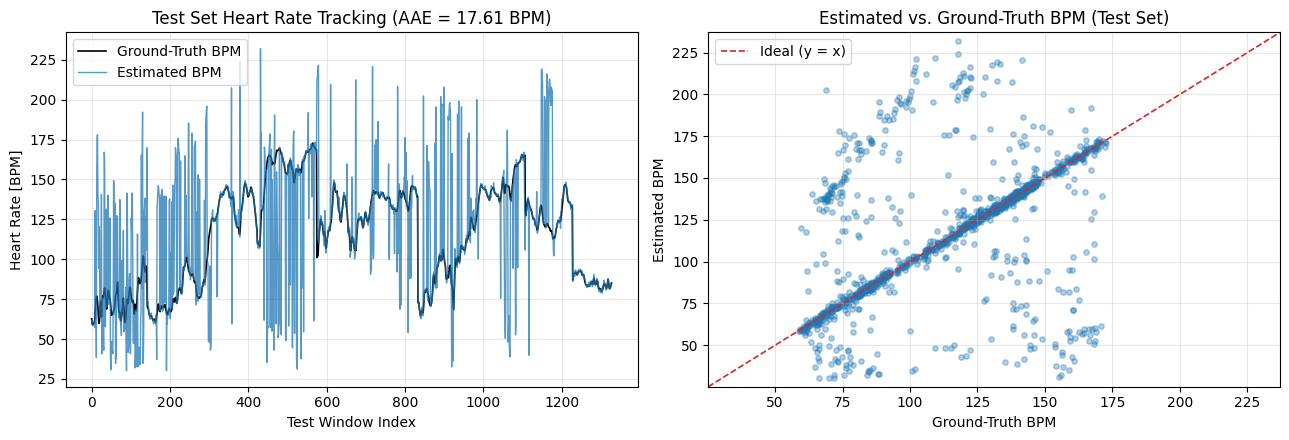

In [5]:
# Visualize Ground-Truth vs. Estimated BPM on the Test Set
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Window-by-window tracking trace
axes[0].plot(y_test, label="Ground-Truth BPM", color="black", lw=1.2)
axes[0].plot(y_test_pred, label="Estimated BPM", color="tab:blue", alpha=0.75, lw=1.0)
axes[0].set_title(f"Test Set Heart Rate Tracking (AAE = {test_aae:.2f} BPM)")
axes[0].set_xlabel("Test Window Index")
axes[0].set_ylabel("Heart Rate [BPM]")
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2. Scatter plot of Estimated vs. Ground-Truth BPM
axes[1].scatter(y_test, y_test_pred, alpha=0.35, s=15, color="tab:blue")
lims = [min(y_test.min(), y_test_pred.min()) - 5, max(y_test.max(), y_test_pred.max()) + 5]
axes[1].plot(lims, lims, "--", color="tab:red", lw=1.2, label="Ideal (y = x)")
axes[1].set_xlim(lims)
axes[1].set_ylim(lims)
axes[1].set_title("Estimated vs. Ground-Truth BPM (Test Set)")
axes[1].set_xlabel("Ground-Truth BPM")
axes[1].set_ylabel("Estimated BPM")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()